# Train Model

In [1]:
!git clone https://github.com/Artlima1/nfl-bigdatabowl-2027.git
%cd nfl-bigdatabowl-2027
!git switch dev

Cloning into 'nfl-bigdatabowl-2027'...
remote: Enumerating objects: 60, done.
remote: Counting objects: 100% (60/60), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 60 (delta 9), reused 54 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (60/60), 1.14 MiB | 8.24 MiB/s, done.
Resolving deltas: 100% (9/9), done.
/kaggle/working/nfl-bigdatabowl-2027
branch 'dev' set up to track 'origin/dev'.
Switched to a new branch 'dev'


In [2]:
!python PlayToVec/preprocess.py --data-dir /kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027 --out-dir /kaggle/working/processed/kinematics --seasons 2023 2024 2025 --max-len 50 --force

2023: 22253 skill tracks -> 21369 not nullified -> 21329 with snap -> 21329 with play_direction
/kaggle/working/nfl-bigdatabowl-2027/PlayToVec/utils/tracking.py:60: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[51.72000122 51.69999695 51.66999817 ... 74.65000153 74.65000153
 74.65000153]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  df.loc[left, "x"] = FIELD_LENGTH - df.loc[left, "x"]
/kaggle/working/nfl-bigdatabowl-2027/PlayToVec/utils/tracking.py:61: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[25.50000076 25.48000031 25.47000008 ... 24.60999947 24.60999947
 24.59999924]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  df.loc[left, "y"] = FIELD_WIDTH - df.loc[left, "y"]
2024: 49926 skill tracks -> 47764 not nullified -> 47730 with

In [3]:
!python PlayToVec/train.py --kin-dir /kaggle/working/processed/kinematics --out /kaggle/working/model.pt

{'train': 107747, 'val': 12816, 'test': 12387}
epoch   1  train 0.4378  val 0.2442
epoch   2  train 0.1803  val 0.1427
epoch   3  train 0.1203  val 0.1012
epoch   4  train 0.0875  val 0.0772
epoch   5  train 0.0694  val 0.0627
epoch   6  train 0.0587  val 0.0557
epoch   7  train 0.0518  val 0.0482
epoch   8  train 0.0468  val 0.0443
epoch   9  train 0.0431  val 0.0403
epoch  10  train 0.0398  val 0.0389
epoch  11  train 0.0374  val 0.0357
epoch  12  train 0.0355  val 0.0341
epoch  13  train 0.0339  val 0.0327
epoch  14  train 0.0323  val 0.0311
epoch  15  train 0.0313  val 0.0305
epoch  16  train 0.0304  val 0.0295
epoch  17  train 0.0295  val 0.0285
epoch  18  train 0.0290  val 0.0281
epoch  19  train 0.0281  val 0.0277
epoch  20  train 0.0277  val 0.0269
epoch  21  train 0.0272  val 0.0265
epoch  22  train 0.0268  val 0.0262
epoch  23  train 0.0266  val 0.0260
epoch  24  train 0.0262  val 0.0257
epoch  25  train 0.0260  val 0.0254
epoch  26  train 0.0258  val 0.0253
epoch  27  train 

# Encoder evaluation: can the embedding tell WRs apart on the same route?

The decoder only sees the embedding `z`, so `z` has to encode the movement. The open question is *what* it encodes. If it captures only the route shape, every WR running a GO should land in the same region. If it also captures **how** a player runs (speed profile, burst, stem, break sharpness), then plays by the same WR should cluster together within a route.

Test, route by route, with the player as the class:
- **within-player scatter** $S_w = \frac{1}{N-K}\sum_k\sum_{i\in k}(z_i-\mu_k)(z_i-\mu_k)^\top$: how much one WR's plays vary
- **between-player scatter** $S_b = \frac{1}{K-1}\sum_k n_k(\mu_k-\mu)(\mu_k-\mu)^\top$: how far apart the WR means are
- **$J = \mathrm{tr}(S_b)/\mathrm{tr}(S_w)$**, a multivariate ANOVA F. It is about 1 if WRs are interchangeable and above 1 if their means differ more than chance would allow. It is calibrated with a permutation test that shuffles player labels within the route.

## Embeddings
`eval.py` writes `embeddings.parquet` and `metrics.json` next to the checkpoint (here `/kaggle/working/`).

In [4]:
!python PlayToVec/eval.py --ckpt /kaggle/working/model.pt --kin-dir /kaggle/working/processed/kinematics

test loss 0.0241  (mean predictor ~ 1.0)
         mse_norm    rmse
x_rel      0.0032  0.3560
y_rel      0.0033  0.3311
s          0.0072  0.1975
a          0.0548  0.3185
dis        0.0080  0.0209
dir_sin    0.0441  0.1280
dir_cos    0.0424  0.1405
o_sin      0.0238  0.1176
o_cos      0.0304  0.1100
saved metrics.json and embeddings.parquet (132950, 64) to /kaggle/working


In [5]:
import sys, json
from os import path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, path.abspath("."))  # cwd is the repo root
from PlayToVec.utils import tracking as trk

DATA_DIR = "/kaggle/input/competitions/nfl-big-data-bowl-2027/nfl-big-data-bowl-2027"
OUT_DIR = "/kaggle/working"

metrics = json.load(open(path.join(OUT_DIR, "metrics.json")))
print(f"{metrics['split']} masked-reconstruction loss: {metrics['loss']:.4f}  (mean predictor ~ 1.0)")
pd.DataFrame({"mse_norm": metrics["mse_norm"], "rmse (original units)": metrics["rmse"]}).round(3)

test masked-reconstruction loss: 0.0241  (mean predictor ~ 1.0)


,mse_norm,rmse (original units)
x_rel,0.003,0.356
y_rel,0.003,0.331
s,0.007,0.198
a,0.055,0.318
dis,0.008,0.021
dir_sin,0.044,0.128
dir_cos,0.042,0.140
o_sin,0.024,0.118
o_cos,0.030,0.110


## WR route plays
Keep WRs (`nfl_position == "WR"`) on plays where they ran a route, across all splits. The encoder never saw player identity, so train-split plays are fair to use. Route labels are the raw `route_ran`: FLAT, WHEEL and ANGLE are different movements, so the usage-profile collapse doesn't apply here. Each embedding dimension is standardized over this set so that no single dimension dominates the traces.

In [6]:
emb = pd.read_parquet(path.join(OUT_DIR, "embeddings.parquet"))
players = pd.read_csv(path.join(DATA_DIR, "players.csv"), usecols=["nfl_id", "display_name", "nfl_position"])
routes = pd.read_csv(path.join(DATA_DIR, "player_play.csv"), usecols=trk.KEYS + ["route_ran"]).dropna(subset=["route_ran"])
names = players.set_index("nfl_id")["display_name"]

zcols = [c for c in emb.columns if c.startswith("z_")]
wr = (emb[emb["split"] != "excluded"]
      .merge(players.loc[players["nfl_position"] == "WR", ["nfl_id"]], on="nfl_id")
      .merge(routes, on=trk.KEYS)
      .reset_index(drop=True))
Z_all = wr[zcols].to_numpy(dtype=np.float64)
Z_all = (Z_all - Z_all.mean(0)) / Z_all.std(0)
print(f"{len(wr)} WR route plays | {wr['nfl_id'].nunique()} WRs | {len(zcols)} embedding dims")

MIN_PLAYS, MIN_PLAYERS = 20, 5  # plays per WR-route, WRs per route
n_wr_route = wr.groupby(["route_ran", "nfl_id"]).size()
pd.DataFrame({
    "plays": wr["route_ran"].value_counts(),
    f"WRs with >= {MIN_PLAYS} plays": (n_wr_route >= MIN_PLAYS).groupby("route_ran").sum(),
}).sort_values("plays", ascending=False)

42706 WR route plays | 105 WRs | 64 embedding dims


,plays,WRs with >= 20 plays
route_ran,,
GO,8531,75
HITCH,6966,70
CROSS,5364,62
IN,4826,63
POST,4309,56
OUT,4134,54
CORNER,3425,55
SLANT,2844,43
SCREEN,1160,15


## Scatter matrices and separability

In [7]:
import numpy as np


def scatter_matrices(Z, y):
    """Pooled within-player S_w (/(N-K)) and between-player S_b (/(K-1)); also raw SS_w, SS_b."""
    classes, inv = np.unique(y, return_inverse=True)
    N, K = len(Z), len(classes)
    counts = np.bincount(inv)
    means = np.zeros((K, Z.shape[1]))
    np.add.at(means, inv, Z)
    means /= counts[:, None]
    mu = Z.mean(0)
    R = Z - means[inv]                       # within-class residuals
    D = (means - mu) * np.sqrt(counts)[:, None]
    SS_w, SS_b = R.T @ R, D.T @ D
    return SS_w / (N - K), SS_b / (K - 1), SS_w, SS_b


def separability(Z, y, ridge=1e-3, n_eig=5):
    S_w, S_b, SS_w, SS_b = scatter_matrices(Z, y)
    ev = np.linalg.eigvals(np.linalg.solve(S_w + ridge * np.eye(len(S_w)), S_b)).real
    return {
        "J": np.trace(S_b) / np.trace(S_w),
        "eta2": np.trace(SS_b) / (np.trace(SS_b) + np.trace(SS_w)),
        "lda_eig": np.sort(ev)[::-1][:n_eig],
    }


def perm_test(Z, y, n_perm=200, seed=0):
    rng = np.random.default_rng(seed)
    J = separability(Z, y)["J"]
    null = np.array([separability(Z, rng.permutation(y))["J"] for _ in range(n_perm)])
    return J, null.mean(), (1 + (null >= J).sum()) / (n_perm + 1)


def route_subset(route):
    # plays of `route` by WRs with at least MIN_PLAYS of it -> (rows of wr, Z, player labels)
    g = wr[wr["route_ran"] == route]
    g = g[g["nfl_id"].map(g["nfl_id"].value_counts()) >= MIN_PLAYS]
    return g, Z_all[g.index], g["nfl_id"].to_numpy()

## Summary across routes
One row per route with at least `MIN_PLAYERS` WRs having `MIN_PLAYS` or more plays of it. `J_null` is the mean J over 200 within-route label shuffles, and `p` is the permutation p-value. `eta2` is the share of embedding variance explained by player identity. `lda_eig1` is the top eigenvalue of $S_w^{-1}S_b$, the separation along the single most discriminative direction.

The **reference** line uses the *route* as the class over all WR plays. It shows how strongly the embedding separates routes, which gives a scale for the player-level J values.

In [8]:
rows = []
for route in wr["route_ran"].unique():
    g, Z, y = route_subset(route)
    if len(np.unique(y)) < MIN_PLAYERS:
        continue
    J, J_null, p = perm_test(Z, y)
    s = separability(Z, y)
    rows.append({"route": route, "n_players": len(np.unique(y)), "n_plays": len(y),
                 "J": J, "J_null": J_null, "p": p, "eta2": s["eta2"], "lda_eig1": s["lda_eig"][0]})
summary = pd.DataFrame(rows).set_index("route").sort_values("J", ascending=False)

ref = separability(Z_all, wr["route_ran"].to_numpy())
print(f"reference, route as class: J = {ref['J']:.2f}, eta2 = {ref['eta2']:.3f}")
summary.round(4)

reference, route as class: J = 644.13, eta2 = 0.142


,n_players,n_plays,J,J_null,p,eta2,lda_eig1
route,,,,,,,
GO,75,8254,5.1365,1.0009,0.005,0.0444,51.9220
POST,56,3960,4.6428,1.0033,0.005,0.0614,45.3305
HITCH,70,6686,3.6668,0.9949,0.005,0.0368,38.1057
CROSS,62,5074,3.2833,0.9937,0.005,0.0384,24.6036
SCREEN,15,725,3.0292,0.9971,0.005,0.0564,24.9648
CORNER,55,3117,3.0126,1.0011,0.005,0.0504,32.4578
OUT,54,3762,2.9663,1.0010,0.005,0.0407,16.2509
IN,63,4569,2.8315,0.9987,0.005,0.0375,24.8062
FLAT,19,630,2.5578,1.0067,0.005,0.0701,24.5487


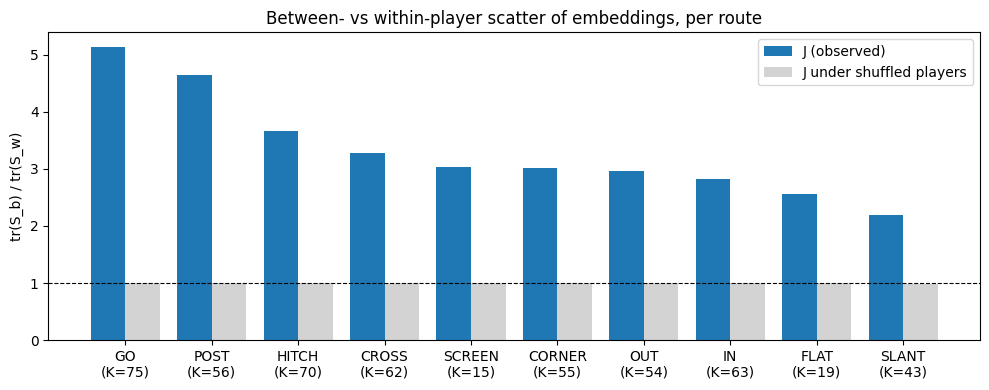

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(summary))
ax.bar(x - 0.2, summary["J"], width=0.4, label="J (observed)")
ax.bar(x + 0.2, summary["J_null"], width=0.4, color="lightgray", label="J under shuffled players")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(x, [f"{r}\n(K={k})" for r, k in zip(summary.index, summary["n_players"])])
ax.set_ylabel("tr(S_b) / tr(S_w)")
ax.set_title("Between- vs within-player scatter of embeddings, per route")
ax.legend()
plt.tight_layout()

## Detail: most-run route
**Per-dimension F.** A one-way ANOVA on each embedding dimension, with the player as the factor. Many dimensions above 1 means player information is spread through the latent space; a few large ones means it is concentrated.

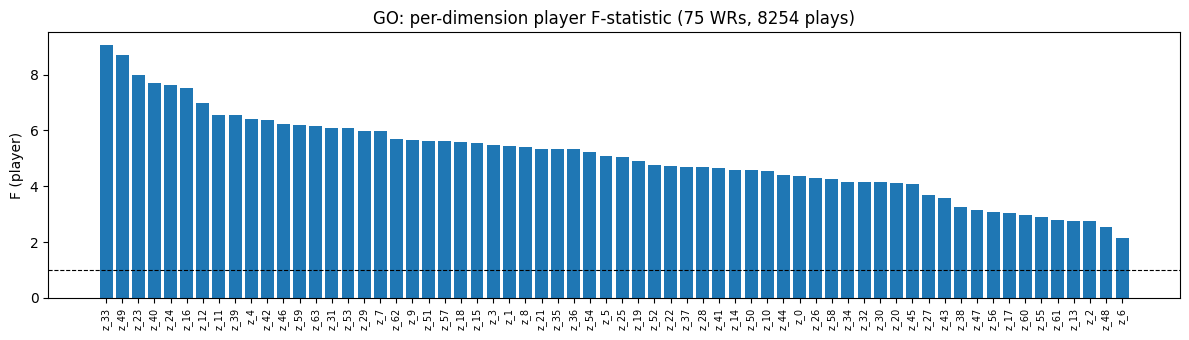

In [10]:
from scipy.stats import f_oneway

route = summary["n_plays"].idxmax()
g, Z, y = route_subset(route)
F = np.array([f_oneway(*[Z[y == k, d] for k in np.unique(y)]).statistic for d in range(Z.shape[1])])

order = np.argsort(F)[::-1]
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(np.arange(len(F)), F[order])
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_xticks(np.arange(len(F)), [zcols[i] for i in order], rotation=90, fontsize=7)
ax.set_ylabel("F (player)")
ax.set_title(f"{route}: per-dimension player F-statistic ({len(np.unique(y))} WRs, {len(y)} plays)")
plt.tight_layout()

**Out-of-sample LDA.** LDA is fit on half of each WR's plays, and the *other* half is projected. Fitting and plotting the same plays would make the separation look better than it is. The held-out classification accuracy is a direct check: can the embedding of one play tell you who ran it, compared with chance?

GO: held-out player accuracy 10.0% vs chance 1.3% (majority class 4.8%), K = 75


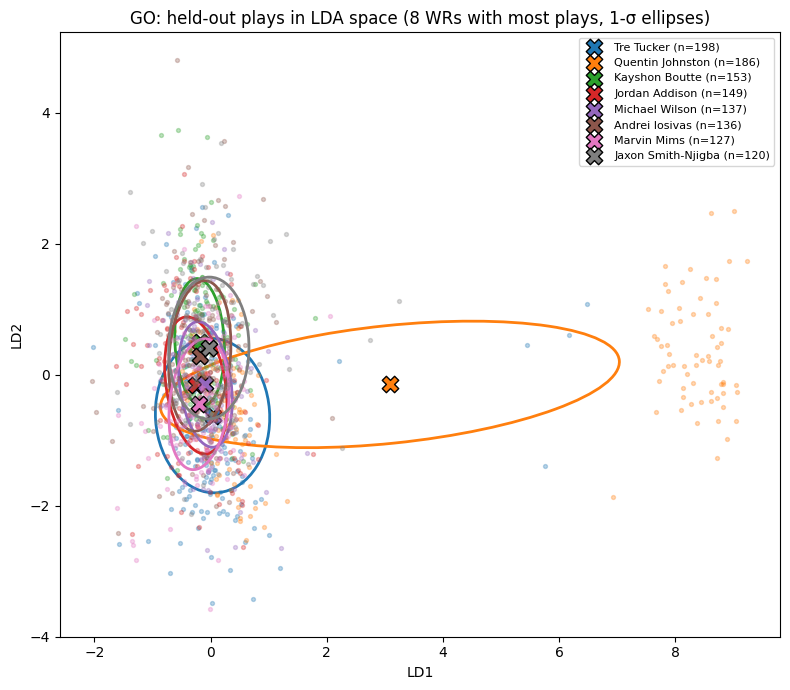

In [11]:
from matplotlib.patches import Ellipse
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split

i_fit, i_hold = train_test_split(np.arange(len(y)), test_size=0.5, stratify=y, random_state=0)
lda = LinearDiscriminantAnalysis(n_components=2).fit(Z[i_fit], y[i_fit])
acc = lda.score(Z[i_hold], y[i_hold])
K = len(np.unique(y))
majority = pd.Series(y[i_hold]).value_counts(normalize=True).iloc[0]
print(f"{route}: held-out player accuracy {acc:.1%} vs chance {1 / K:.1%} (majority class {majority:.1%}), K = {K}")

P, y_hold = lda.transform(Z[i_hold]), y[i_hold]
top = pd.Series(y_hold).value_counts().index[:8]
fig, ax = plt.subplots(figsize=(8, 7))
for k, color in zip(top, plt.cm.tab10.colors):
    pts = P[y_hold == k]
    mu = pts.mean(0)
    vals, vecs = np.linalg.eigh(np.cov(pts.T))
    angle = np.degrees(np.arctan2(vecs[1, -1], vecs[0, -1]))
    ax.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.3, color=color)
    ax.add_patch(Ellipse(mu, 2 * np.sqrt(vals[-1]), 2 * np.sqrt(vals[0]), angle=angle, fill=False, color=color, lw=2))
    ax.scatter(*mu, color=color, marker="X", s=140, edgecolor="k", label=f"{names.get(k, k)} (n={len(pts)})")
ax.set_xlabel("LD1")
ax.set_ylabel("LD2")
ax.set_title(f"{route}: held-out plays in LDA space (8 WRs with most plays, 1-σ ellipses)")
ax.legend(fontsize=8)
plt.tight_layout()

## Reading the results
- **J clearly above `J_null`, with p < 0.05:** WR means differ more than chance on the same route, so the embedding carries player-specific movement information.
- **J ≈ `J_null`:** within a route, the embedding mostly encodes the route itself, and one WR's play is interchangeable with another's.
- Compare player J values with the route-as-class reference: the player signal is expected to be much weaker than the route signal. The question is whether it is clearly non-zero.

**Confound.** Player identity is entangled with team, QB, offensive scheme and season (for example, route depth and timing are coached). A high J can partly reflect context rather than the athlete. Next checks: shuffle labels *within team-season*, or compare players who changed teams.